# Imports

In [1]:
import torch 
import torch.nn as nn
import math
import typing
from typing import List, Union
import pandas as pd
import torch.nn.functional as F
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt
from torch.utils.data import Dataset

from torch.utils.data import DataLoader
import random

from torch.nn.utils.rnn import pad_sequence
import torch
from torch.utils.data import Dataset
import random
import torch
import torch.nn as nn
import math
import matplotlib.pyplot as plt
import pandas as pd
import os
from PIL import Image
import glob

In [2]:
import os
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"

# Dataset

In [3]:
df = pd.read_csv(r'bert_trainset.csv')
print(df.shape)
df.head(2)

(18612, 11)


,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.10,"[0.4026232822198967, 0.7417207576216707]",0.009847,"[-0.09281291539991132, -0.0463919936574575]",0.189775,"[-0.9126425051271226, -0.40875867921707787]",CBDJIFZNJYACJEFEMDQC,240,0.110650,235.0,1
1,0.15,"[0.3976118494689565, 0.7399640928963773]",0.015157,"[-0.10022865501880363, -0.035133294505866886]",-2.527519,"[-0.923718739965175, -0.3830713894787102]",IFZNCBDJJYACJEFEIEEY,846,0.390041,240.0,1


In [4]:
token_to_ps = {pid:ps for pid, ps in zip(df['position_state_id'], df['position_state'])}
ps_to_token = {ps:pid for pid, ps in zip(df['position_state_id'], df['position_state'])}

In [5]:
df['position_state_id'].nunique()

2169

In [6]:
df['position_state_id'].describe()

count    18612.000000
mean      1047.854825
std        620.245382
min          0.000000
25%        497.000000
50%       1021.000000
75%       1580.000000
max       2168.000000
Name: position_state_id, dtype: float64

In [103]:
import seaborn as sns

<Axes: xlabel='position_state_id', ylabel='Count'>

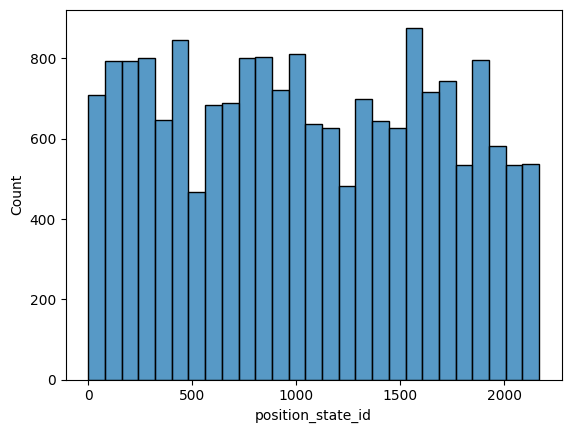

In [104]:
sns.histplot(df, x='position_state_id')#.value_counts(normalize=True).hist(grid=False, )

In [ ]:
df.groupby('position_state_id', as_index=False)

AttributeError: 'DataFrameGroupBy' object has no attribute 'index'

<Axes: xlabel='position_state_id', ylabel='Count'>

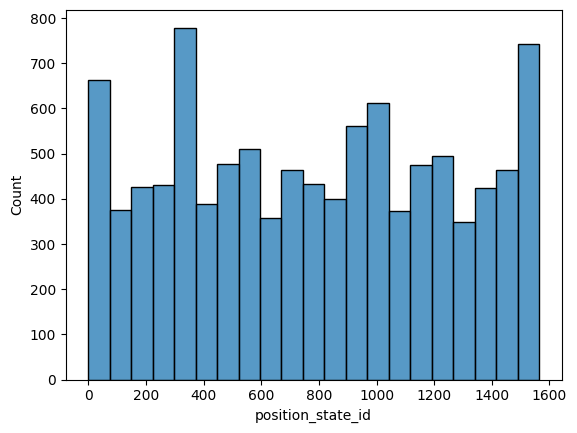

In [107]:
sns.histplot(apd, x='position_state_id',stat='count')#.value_counts(normalize=True).hist(grid=False, )

In [112]:
apd.head(5)

,X,Y,pos,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,obj_2_pos,obj_2_name,obj_3_pos,...,dist_to_obj_43,dist_to_obj_44,dist_to_obj_45,dist_to_obj_46,dist_to_obj_47,dist_to_obj_48,dist_to_obj_49,position_state,position_state_id,normalized_position_state_id
0,0.00,0.0,"[0.0, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,1.096278,0.964612,0.764495,0.786268,0.860513,0.439066,0.877293,WGXVEXKNJHXTEZUESUYI,1469,0.677271
1,0.01,0.0,"[0.01, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,1.092082,0.962750,0.764552,0.783404,0.852275,0.437503,0.869214,WGXVEXKNJHXTEZUESUYI,1469,0.677271
2,0.02,0.0,"[0.02, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,1.087961,0.960989,0.764740,0.780657,0.844075,0.436164,0.861176,WGXVEXKNJHXTEZUESUYI,1469,0.677271
3,0.03,0.0,"[0.03, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,1.083917,0.959328,0.765058,0.778029,0.835914,0.435050,0.853179,WGXVEXKNJHXTEZUESUYI,1469,0.677271
4,0.04,0.0,"[0.04, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,1.079951,0.957769,0.765507,0.775521,0.827794,0.434164,0.845224,WGXVEXKNJHXTEZUESUYI,1469,0.677271


In [ ]:
apd.groupby('position_state_id', as_index=False).agg({''})

,position_state_id,size
0,0,5
1,1,6
2,2,2
3,3,1
4,4,1
...,...,...
1560,1560,34
1561,1561,6
1562,1562,6
1563,1563,2


<Axes: >

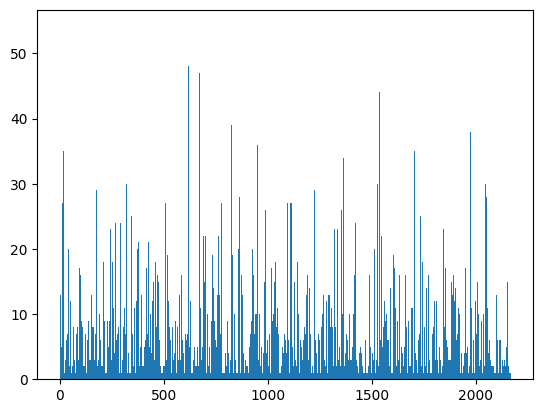

In [8]:
df['position_state_id'].hist(grid=False, bins=range(df['position_state_id'].nunique()))

## tokenized dataset

In [9]:
df['position_state_id'].head()

0    240
1    846
2    858
3    859
4    870
Name: position_state_id, dtype: int64

# Classes

In [10]:


def collate_masked_batch(batch, pad_token_id=0):
    """
    Recebe uma lista de (input_ids, target_ids) e aplica padding para o maior comprimento.
    """
    input_ids, target_ids = zip(*batch)
    
    input_ids_padded = pad_sequence(input_ids, batch_first=True, padding_value=pad_token_id)
    target_ids_padded = pad_sequence(target_ids, batch_first=True, padding_value=-100)  # ignorado pela loss

    return input_ids_padded, target_ids_padded


In [11]:


class TrajectoryMaskingDataset(Dataset):
    def __init__(self, full_sequence, mask_token_id, min_len=5, max_len=15, mask_prob=0.3):
        """
        full_sequence: lista 1D com todos os tokens da trajetória completa (ex: [12, 32, 99, ...])
        mask_token_id: ID reservado para o token [MASK]
        min_len, max_len: tamanho aleatório da janela de corte
        mask_prob: probabilidade de mascarar um token intermediário
        """
        self.full_sequence = full_sequence
        self.mask_token_id = mask_token_id
        self.min_len = min_len
        self.max_len = max_len
        self.mask_prob = mask_prob

        # Gera os índices de início para as janelas baseando-se no menor comprimento possível
        self.start_indices = list(range(0, len(full_sequence) - min_len))

    def __len__(self):
        return len(self.start_indices)

    def __getitem__(self, idx):
        start = self.start_indices[idx]
        seq_len = random.randint(self.min_len, self.max_len)
        end = min(start + seq_len, len(self.full_sequence))

        seq = self.full_sequence[start:end]

        input_ids = []
        target_ids = []

        for i, token in enumerate(seq):
            if i == 0 or i == len(seq) - 1:
                input_ids.append(token)
                target_ids.append(-100)
            elif random.random() < self.mask_prob:
                input_ids.append(self.mask_token_id)
                target_ids.append(token)
            else:
                input_ids.append(token)
                target_ids.append(-100)

        return torch.tensor(input_ids, dtype=torch.long), torch.tensor(target_ids, dtype=torch.long)


In [12]:



class TrajectoryBERT(nn.Module):
    def __init__(self, vocab_size, embed_size, num_layers, num_heads, hidden_dim, dropout=0.1, max_len=512, pad_token_id=0):
        super().__init__()
        self.pad_token_id = pad_token_id
        self.embedding = nn.Embedding(vocab_size, embed_size)
        self.position_embedding = nn.Embedding(max_len, embed_size)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_size,
            nhead=num_heads,
            dim_feedforward=hidden_dim,
            dropout=dropout,
            batch_first=True
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.fc_out = nn.Linear(embed_size, vocab_size)

    def forward(self, x):
        """
        x: [batch_size, seq_len] tensor de input_ids (com paddings, [MASK], etc.)
        """
        batch_size, seq_len = x.size()
        device = x.device

        # Gera posições e aplica embedding
        positions = torch.arange(seq_len, device=device).unsqueeze(0).expand(batch_size, seq_len)
        x_embed = self.embedding(x) + self.position_embedding(positions)

        # Gera attention_mask para ignorar os pads
        attention_mask = (x == self.pad_token_id)  # shape: [batch_size, seq_len], bool
        # -> Transformer usa True para ignorar posições (inverso do HuggingFace)

        # Aplica encoder
        encoded = self.encoder(x_embed, src_key_padding_mask=attention_mask)
        logits = self.fc_out(encoded)

        return logits


In [13]:
# Hiperparâmetros
embed_size = 512
num_layers = 2
num_heads = 4
hidden_dim = 1024
mask_token_id = df['position_state_id'].nunique()
pad_token_id = df['position_state_id'].nunique() + 1
vocab_size = pad_token_id + 1
seq_length = 7
dropout = 0.3
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_epochs = 30
# Simulando dados
sequences = df['position_state_id'].values

device, vocab_size

(device(type='cuda'), 2171)

In [14]:
sequences

array([ 240,  846,  858, ..., 1131,  867,  881])

In [15]:
mask_token_id = 469 + 1  # ou qualquer valor fora do intervalo real
pad_token_id = 0         # se 0 não for usado no vocabulário real

dataset = TrajectoryMaskingDataset(sequences, mask_token_id , max_len=seq_length)
loader = DataLoader(dataset, batch_size=16, shuffle=True, collate_fn=lambda x: collate_masked_batch(x, pad_token_id))


In [16]:
for x, y in loader:
    print("Input shape:", x.shape)
    print("Target shape:", y.shape)
    print("Input:", x[0])
    print("Target:", y[0])
    break


Input shape: torch.Size([16, 7])
Target shape: torch.Size([16, 7])
Input: tensor([2059,  470, 2074,  470, 2069, 2061, 2051])
Target: tensor([-100, 2060, -100, 2073, -100, -100, -100])


In [17]:
np.max(sequences)

2168

In [18]:
# Dataset e dataloaders
dataset = TrajectoryMaskingDataset(sequences, mask_token_id)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = torch.utils.data.random_split(dataset, [train_size, val_size])

In [19]:
# Inicialização do modelo e treino
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = TrajectoryBERT(vocab_size, embed_size=embed_size, num_layers=num_layers, num_heads=num_heads, hidden_dim=hidden_dim,
                       dropout=dropout, pad_token_id=pad_token_id).to(device)

In [20]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
criterion = nn.CrossEntropyLoss(ignore_index=-100)

In [21]:

train_losses = []
val_losses = []
train_perplexities = []
val_perplexities = []

for epoch in range(num_epochs):
    model.train()
    train_loss = 0.0
    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True,
                          collate_fn=lambda x: collate_masked_batch(x, pad_token_id))
    
    val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False,
                        collate_fn=lambda x: collate_masked_batch(x, pad_token_id))
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        output = model(x)
        loss = criterion(output.view(-1, vocab_size), y.view(-1))
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for x_val, y_val in val_loader:
            x_val, y_val = x_val.to(device), y_val.to(device)
            val_output = model(x_val)
            v_loss = criterion(val_output.view(-1, vocab_size), y_val.view(-1))
            val_loss += v_loss.item()

    # Cálculo médio das perdas
    avg_train_loss = train_loss / len(train_loader)
    avg_val_loss = val_loss / len(val_loader)

    # Cálculo da perplexidade
    train_ppl = math.exp(avg_train_loss)
    val_ppl = math.exp(avg_val_loss)

    # Armazenamento
    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    train_perplexities.append(train_ppl)
    val_perplexities.append(val_ppl)

    if (epoch + 1) % max(1, num_epochs // 10) == 0 or (epoch + 1) == num_epochs:
        print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | "
            f"Train PPL: {train_ppl:.2f} | Val PPL: {val_ppl:.2f}")


/home/mgteus/workspace/navitrans/.nav/lib/python3.8/site-packages/torch/nn/modules/transformer.py:409: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. (Triggered internally at ../aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(output, src_key_padding_mask.logical_not(), mask_check=False)


Epoch 3/30 | Train Loss: 4.9073 | Val Loss: 3.7201 | Train PPL: 135.28 | Val PPL: 41.27
Epoch 6/30 | Train Loss: 2.4131 | Val Loss: 1.9131 | Train PPL: 11.17 | Val PPL: 6.77
Epoch 9/30 | Train Loss: 1.6923 | Val Loss: 1.4069 | Train PPL: 5.43 | Val PPL: 4.08
Epoch 12/30 | Train Loss: 1.3356 | Val Loss: 1.1233 | Train PPL: 3.80 | Val PPL: 3.07
Epoch 15/30 | Train Loss: 1.1766 | Val Loss: 0.9735 | Train PPL: 3.24 | Val PPL: 2.65
Epoch 18/30 | Train Loss: 1.0561 | Val Loss: 0.8686 | Train PPL: 2.88 | Val PPL: 2.38
Epoch 21/30 | Train Loss: 0.9816 | Val Loss: 0.8290 | Train PPL: 2.67 | Val PPL: 2.29
Epoch 24/30 | Train Loss: 0.9007 | Val Loss: 0.7477 | Train PPL: 2.46 | Val PPL: 2.11
Epoch 27/30 | Train Loss: 0.8400 | Val Loss: 0.6845 | Train PPL: 2.32 | Val PPL: 1.98
Epoch 30/30 | Train Loss: 0.8022 | Val Loss: 0.6621 | Train PPL: 2.23 | Val PPL: 1.94


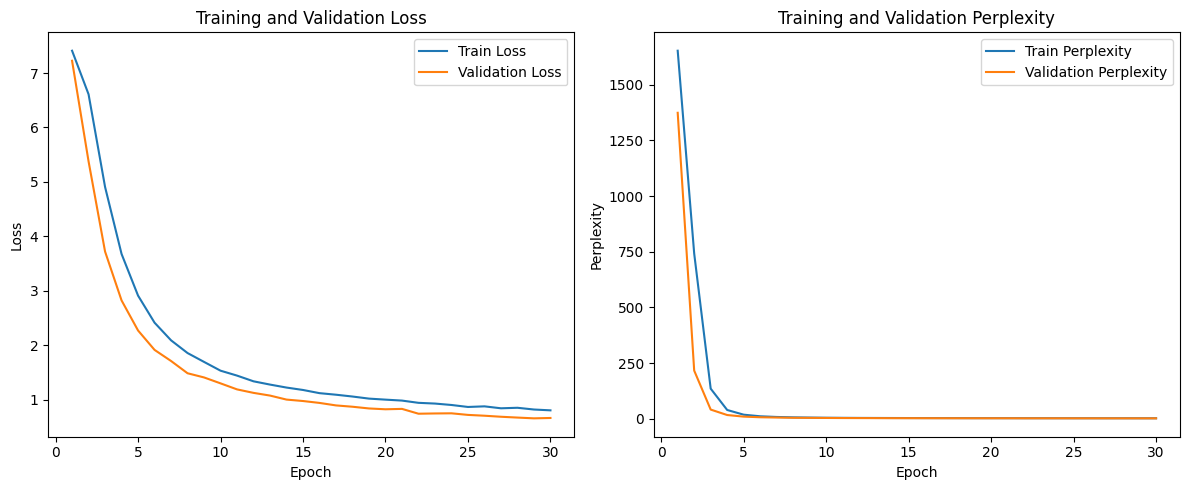

In [22]:
# Calcula perplexidade a partir das losses
train_perplexities = [np.exp(l) for l in train_losses]
val_perplexities = [np.exp(l) for l in val_losses]

# Plot da loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, int(num_epochs) + 1), train_losses, label='Train Loss')
plt.plot(range(1, int(num_epochs) + 1), val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
# plt.grid(True)

# Plot da perplexidade
plt.subplot(1, 2, 2)
plt.plot(range(1, int(num_epochs) + 1), train_perplexities, label='Train Perplexity')
plt.plot(range(1, int(num_epochs) + 1), val_perplexities, label='Validation Perplexity')
plt.xlabel('Epoch')
plt.ylabel('Perplexity')
plt.title('Training and Validation Perplexity')
plt.legend()
# plt.grid(True)

plt.tight_layout()
plt.show()


# Vizz Predictions

In [23]:
def visualize_predictions(model, x, y, mask_token_id, id_to_token=None):
    """
    Exibe a entrada x, os targets y e as previsões do modelo nas posições mascaradas.
    """
    if id_to_token is None:
        id_to_token = {}

    model.eval()
    device = next(model.parameters()).device
    x = x.unsqueeze(0).to(device)
    y = y.to(device)

    with torch.no_grad():
        logits = model(x)
        preds = torch.argmax(logits, dim=-1).squeeze(0).cpu()

    x = x.squeeze(0).cpu()
    y = y.cpu()

    # Vetor de entrada
    entrada_str = [id_to_token.get(tok.item(), str(tok.item())) for tok in x]
    target_str = [
        id_to_token.get(t.item(), str(t.item())) if t.item() != -100 else '-' for t in y
    ]

    print("\nEntrada (x):")
    print("[" + " ".join(entrada_str) + "]")

    print("\nTarget (y):")
    print("[" + " ".join(target_str) + "]\n")

    print(f"{'Posição':<8} {'Token em x':<14} {'Esperado (y)':<20} {'Previsto':<20} {'Correto'}")
    print("-" * 80)

    for i in range(len(x)):
        if y[i].item() == -100:
            continue

        input_token_id = x[i].item()
        target_token_id = y[i].item()
        predicted_token_id = preds[i].item()

        input_token = id_to_token.get(input_token_id, str(input_token_id))
        target_token = id_to_token.get(target_token_id, str(target_token_id))
        predicted_token = id_to_token.get(predicted_token_id, str(predicted_token_id))

        correto = "SIM" if target_token_id == predicted_token_id else "NÃO"
        print(f"{i:<8} {input_token:<14} {target_token:<20} {predicted_token:<20} {correto}")
    print("-" * 80)


In [24]:
x_batch, y_batch = next(iter(val_loader))
example_x = x_batch[0]
example_y = y_batch[0]

visualize_predictions(model, example_x, example_y, mask_token_id)


Entrada (x):
[2153 470 470 470 2012 470 1708 470 287 0 0 0 0 0 0]

Target (y):
[- 2152 2149 2044 - 293 - 288 - - - - - - -]

Posição  Token em x     Esperado (y)         Previsto             Correto
--------------------------------------------------------------------------------
1        470            2152                 2152                 SIM
2        470            2149                 1717                 NÃO
3        470            2044                 2044                 SIM
5        470            293                  293                  SIM
7        470            288                  288                  SIM
--------------------------------------------------------------------------------


In [25]:
def expand_trajectory(model, start_token, end_token, mask_token_id, pad_token_id, max_len=12, id_to_token=None):
    """
    Expande uma sequência entre start_token e end_token, preenchendo iterativamente
    tokens intermediários e mostrando o histórico de predições.
    """
    device = next(model.parameters()).device
    sequence = [start_token, end_token]
    step = 1

    while len(sequence) < max_len:
        print(f"\n=== Etapa {step} ===")
        print("Sequência atual:", [id_to_token.get(t, str(t)) if id_to_token else t for t in sequence])

        # Inserção de MASKs entre os pares
        new_sequence = []
        for i in range(len(sequence) - 1):
            new_sequence.append(sequence[i])
            new_sequence.append(mask_token_id)
        new_sequence.append(sequence[-1])
        sequence = new_sequence

        print("Com [MASK]:     ", [id_to_token.get(t, str(t)) if id_to_token else t for t in sequence])

        # Predição
        input_tensor = torch.tensor(sequence, dtype=torch.long).unsqueeze(0).to(device)
        with torch.no_grad():
            logits = model(input_tensor)
            predictions = torch.argmax(logits, dim=-1).squeeze(0).cpu().tolist()

        # Substituição dos MASKs e exibição
        updated_sequence = []
        for i, token in enumerate(sequence):
            if token == mask_token_id:
                predicted_token = predictions[i]
                updated_sequence.append(predicted_token)
                print(f"Predição na posição {i}: {id_to_token.get(predicted_token, predicted_token) if id_to_token else predicted_token}")
            else:
                updated_sequence.append(token)

        sequence = updated_sequence
        print("Após predição: ", [id_to_token.get(t, str(t)) if id_to_token else t for t in sequence])

        if len(sequence) >= max_len:
            print("\nLimite de comprimento atingido.")
            break

        step += 1

    print("\n=== Trajetória Final ===")
    print([id_to_token.get(t, str(t)) if id_to_token else t for t in sequence])
    return sequence


In [33]:
# start_token = 200
# end_token = 1031
# max_len = 15

In [34]:
# expand_trajectory(
#     model,
#     start_token=start_token,
#     end_token=end_token,
#     mask_token_id=mask_token_id,
#     pad_token_id=pad_token_id,
#     max_len=max_len,
#     # id_to_token=id_to_token  # ou None
# )

In [35]:

def plot_position_states_w_title(apd, grupos_destacados, title=None):
    """
    Plota os pontos do DataFrame apd (com colunas X, Y e position_state_id),
    destacando apenas os grupos na lista grupos_destacados, com anotações.

    Parâmetros:
    - apd: DataFrame com colunas 'X', 'Y' e 'position_state_id'
    - grupos_destacados: lista de valores de position_state_id a serem coloridos e anotados
    """
    # Criação da máscara de seleção
    destaque_mask = apd['position_state_id'].isin(grupos_destacados)

    # Define cores: branco ou cinza claro para os pontos não destacados
    cor_base = '#e0e0e0'
    
    plt.figure(figsize=(12, 12))

    # Plota todos os pontos em cinza claro
    plt.scatter(apd['X'], apd['Y'], color=cor_base, s=10, label='Outros')

    # Plota apenas os pontos destacados com colormap
    destacados = apd[destaque_mask]
    if not destacados.empty:
        scatter = plt.scatter(destacados['X'], destacados['Y'],
                              c=destacados['position_state_id'], cmap='tab10', s=25, label='Destacados')

        # Anotar a média dos grupos destacados
        medias = destacados.groupby('position_state_id')[['X', 'Y']].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
                         fontsize=7, alpha=0.9, ha='center', va='center', fontweight='bold')

        # Adiciona colorbar apenas se houver grupos destacados
        cbar = plt.colorbar(scatter)
        cbar.set_label('position_state_id destacado')

    # Layout
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title('Grupos destacados por position_state_id' if not title else title)
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.legend()
    # plt.show()


In [36]:
apd = pd.read_parquet(r'apd.gzip')
apd.shape

(10201, 156)

In [68]:
def plot_position_states(apd, grupos_destacados):
    """
    Plota os pontos do DataFrame apd (com colunas X, Y e position_state_id),
    destacando apenas os grupos na lista grupos_destacados, com anotações.

    Parâmetros:
    - apd: DataFrame com colunas 'X', 'Y' e 'position_state_id'
    - grupos_destacados: lista de valores de position_state_id a serem coloridos e anotados
    """
    # Criação da máscara de seleção
    destaque_mask = apd['position_state_id'].isin(grupos_destacados)

    # Define cores: branco ou cinza claro para os pontos não destacados
    cor_base = '#e0e0e0'
    
    plt.figure(figsize=(12, 12))

    # Plota todos os pontos em cinza claro
    plt.scatter(apd['X'], apd['Y'], color=cor_base, s=10, label='Outros')

    # Plota apenas os pontos destacados com colormap
    destacados = apd[destaque_mask]
    if not destacados.empty:
        scatter = plt.scatter(destacados['X'], destacados['Y'],
                              c=destacados['position_state_id'], cmap='tab10', s=25, label='Destacados')

        # Anotar a média dos grupos destacados
        medias = destacados.groupby('position_state_id')[['X', 'Y']].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
                         fontsize=7, alpha=0.9, ha='center', va='center', fontweight='bold')

        # Adiciona colorbar apenas se houver grupos destacados
        cbar = plt.colorbar(scatter)
        cbar.set_label('position_state_id destacado')

    # Layout
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title('Grupos destacados por position_state_id')
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.legend()
    plt.show()


In [77]:
def plot_position_states_w_region(apd, region):
    """
    Plota os pontos do DataFrame apd, destacando grupos (position_state_id)
    que possuem pontos dentro da região [xmin, xmax, ymin, ymax].

    Parâmetros:
    - apd: DataFrame com colunas 'X', 'Y', 'position_state_id'
    - region: lista ou tupla com [xmin, xmax, ymin, ymax]
    """
    xmin, xmax, ymin, ymax = region

    # Filtrar os pontos que estão dentro da região
    dentro = apd[(apd['X'] >= xmin) & (apd['X'] <= xmax) &
                 (apd['Y'] >= ymin) & (apd['Y'] <= ymax)]

    # Identificar os grupos que têm pelo menos um ponto na região
    grupos_destacados = dentro['position_state_id'].unique()
    print('Grupos Destados', grupos_destacados)

    # Máscara dos grupos destacados
    destaque_mask = apd['position_state_id'].isin(grupos_destacados)

    # Plot
    plt.figure(figsize=(12, 12))

    # Pontos não destacados (fundo)
    cor_base = '#e0e0e0'
    plt.scatter(apd['X'], apd['Y'], color=cor_base, s=10, label='Outros')

    # Pontos destacados (na região)
    destacados = apd[destaque_mask]
    if not destacados.empty:
        scatter = plt.scatter(destacados['X'], destacados['Y'],
                              c=destacados['position_state_id'], cmap='tab10', s=25, label='Destacados')

        # Anotar centro de massa de cada grupo destacado
        medias = destacados.groupby('position_state_id')[['X', 'Y']].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
                         fontsize=7, alpha=0.9, ha='center', va='center', fontweight='bold')

        # Colorbar
        cbar = plt.colorbar(scatter)
        cbar.set_label('position_state_id destacado')

    # Desenhar a região no gráfico
    plt.plot([xmin, xmax, xmax, xmin, xmin],
             [ymin, ymin, ymax, ymax, ymin], color='black', linestyle='--', linewidth=1.2, label='Região')

    # Layout
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title('Grupos destacados por interseção com região')
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.legend()
    plt.show()


Grupos Destados [ 1 10  9  5  7 32 33 24]


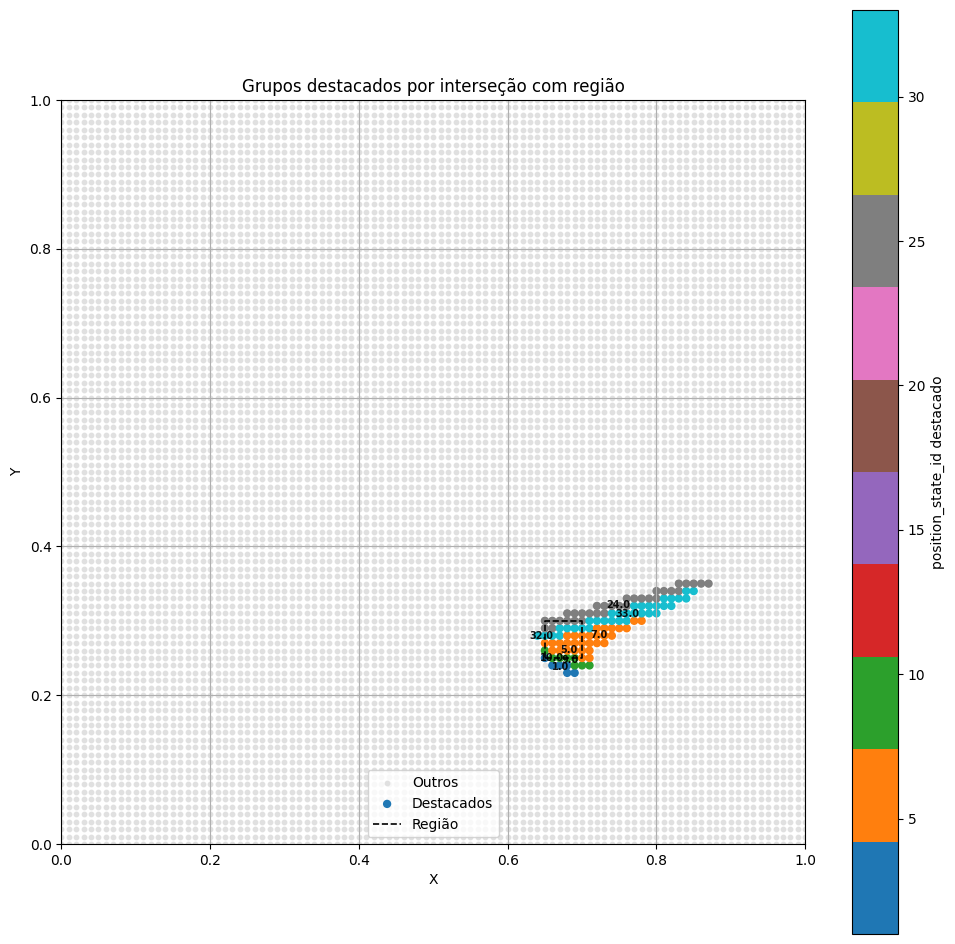

In [81]:
plot_position_states_w_region(apd, region=[0.65, 0.7, 0.25, 0.3])

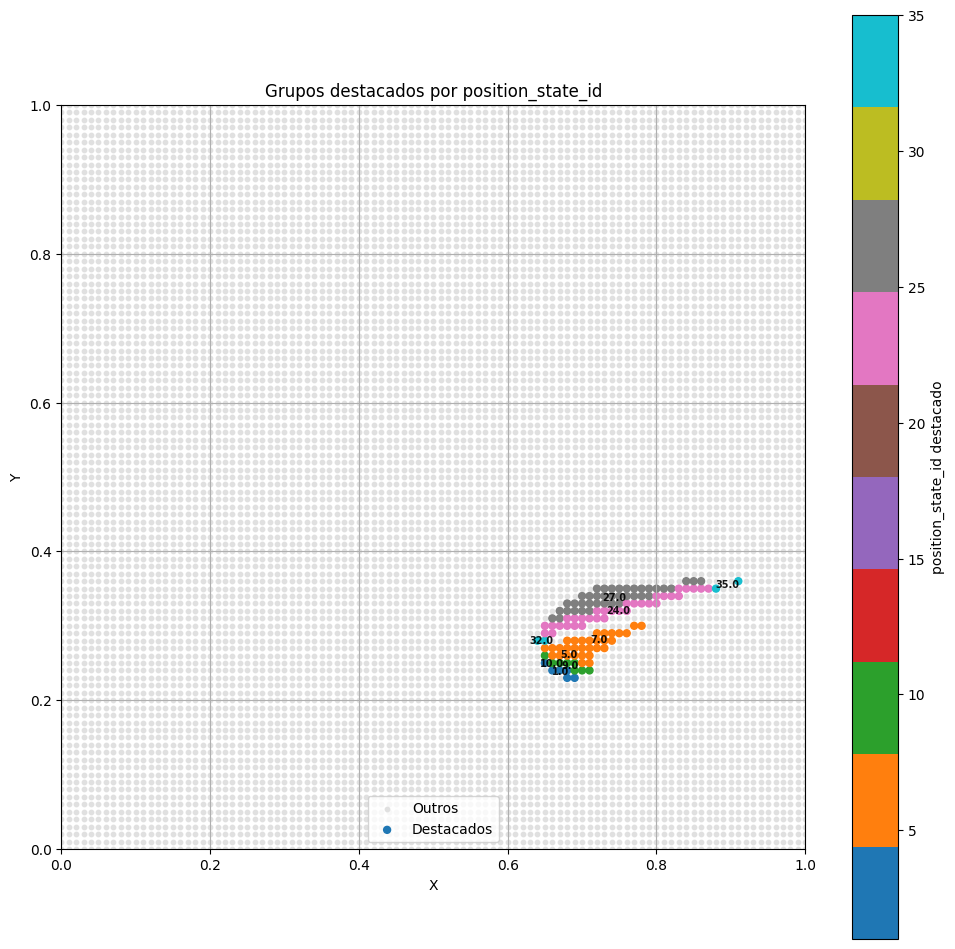

In [84]:
plot_position_states(apd, [5, 7, 1,9, 10, 27, 24,32,  35])

In [95]:

def gerar_graficos_expansao(model, start_token, end_token, mask_token_id,
                             max_len,  apd, pasta_destino="imgs"):
    """
    Executa a expansão da trajetória e salva os gráficos das etapas destacando os grupos preditos.

    Parâmetros:
    - model: modelo de linguagem
    - start_token, end_token, mask_token_id, pad_token_id: tokens especiais
    - max_len: tamanho máximo da sequência
    - id_to_token: dicionário de id para string
    - apd: DataFrame com colunas 'X', 'Y', 'position_state_id'
    - pasta_destino: pasta onde os gráficos serão salvos
    """
    os.makedirs(pasta_destino, exist_ok=True)
    step = 0
    # Salva gráfico com os novos IDs destacados
    caminho_arquivo = os.path.join(pasta_destino, f"etapa_{step:02}.png")
    device = next(model.parameters()).device
    sequence = [start_token, end_token]
    plot_position_states_w_title(apd, grupos_destacados=sequence, title=f"Passo {step:02} | {sequence[0]}->{sequence[1]}")
    plt.savefig(caminho_arquivo)
    plt.close()
    step +=1
    

    while len(sequence) < max_len:
        # Inserir [MASK] entre os pares
        new_sequence = []
        for i in range(len(sequence) - 1):
            new_sequence.append(sequence[i])
            new_sequence.append(mask_token_id)
        new_sequence.append(sequence[-1])
        sequence = new_sequence

        # Predição
        input_tensor = torch.tensor(sequence, dtype=torch.long).unsqueeze(0).to(device)
        with torch.no_grad():
            logits = model(input_tensor)
            predictions = torch.argmax(logits, dim=-1).squeeze(0).cpu().tolist()

        # Substituição dos MASKs
        updated_sequence = []
        novos_ids = []
        for i, token in enumerate(sequence):
            if token == mask_token_id:
                predicted_token = predictions[i]
                updated_sequence.append(predicted_token)
                novos_ids.append(predicted_token)
            else:
                updated_sequence.append(token)

        sequence = updated_sequence
        print(sequence)
        
        # print(novos_ids)
        caminho_arquivo = os.path.join(pasta_destino, f"etapa_{step:02}.png")
        plot_position_states_w_title(apd, grupos_destacados=updated_sequence, title=f"Passo {step:02}")
        plt.savefig(caminho_arquivo)
        plt.close()

        if len(sequence) >= max_len:
            break
        step += 1

    return


Grupos Destados [ 875  873  842  819  822  874  843  878  879  844  823  871  880 1180
  848 1182 1181 1179  702 1177 1178 1156]


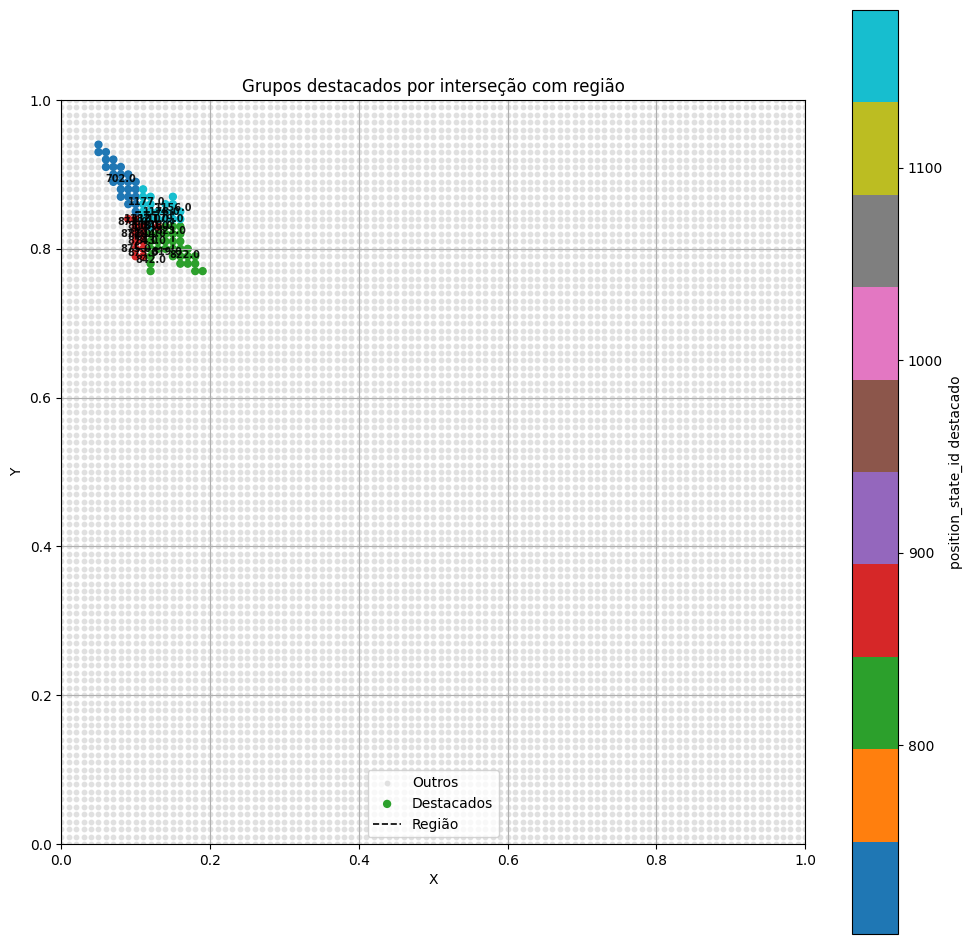

In [100]:
plot_position_states_w_region(apd, region=[0.1, 0.15, 0.8, 0.85])

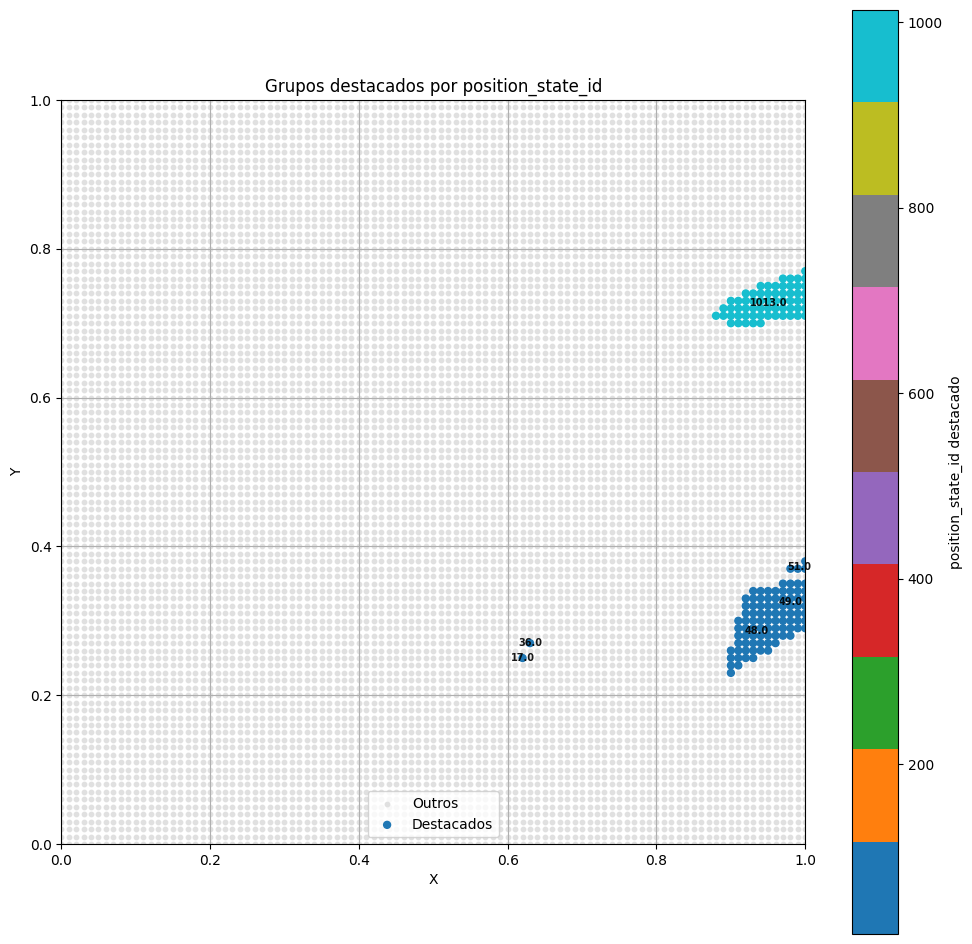

In [101]:
plot_position_states(apd, [17, 36, 48,49, 51,  1013])

In [96]:
start_token = 48
end_token = 1013
max_len = 20

In [97]:
gerar_graficos_expansao(
    model,
    start_token=start_token,
    end_token=end_token,
    mask_token_id=mask_token_id,
    max_len=max_len,
    apd=apd
)

[48, 51, 1013]
[48, 49, 51, 48, 1013]
[48, 51, 49, 48, 51, 49, 48, 51, 1013]
[48, 49, 51, 48, 49, 51, 48, 49, 51, 48, 49, 51, 48, 17, 51, 36, 1013]
[48, 51, 49, 48, 51, 49, 48, 51, 49, 48, 51, 49, 48, 51, 49, 48, 51, 48, 48, 48, 49, 49, 51, 48, 48, 48, 17, 48, 51, 49, 36, 48, 1013]


In [56]:
def gerar_gif(pasta_imagens, nome_gif='trajetoria_animada.gif', duracao=1000):
    """
    Gera um GIF animado com os gráficos salvos.

    Parâmetros:
    - pasta_imagens: pasta onde estão os arquivos PNG
    - nome_gif: nome do arquivo de saída
    - duracao: duração entre os frames (em ms)
    """
    arquivos = sorted(glob.glob(os.path.join(pasta_imagens, "*.png")))
    imagens = [Image.open(arquivo) for arquivo in arquivos]

    if imagens:
        imagens[0].save(nome_gif, save_all=True, append_images=imagens[1:], duration=duracao, loop=0)
        print(f"GIF salvo como {nome_gif}")
    else:
        print("Nenhuma imagem encontrada para criar o GIF.")


In [85]:
# filepaths
fp_in = r"imgs/*.png"
fp_out = "gif_t1.gif"

# # # https://pillow.readthedocs.io/en/stable/handbook/image-file-formats.html#gif
img, *imgs = [Image.open(f) for f in sorted(glob.glob(fp_in))]
img.save(fp=fp_out, format='GIF', append_images=imgs,
         save_all=True, duration=500, loop=0)   

In [59]:
for i in sorted(glob.glob(fp_in)):
    print(i)

imgs/etapa_00.png
imgs/etapa_01.png
imgs/etapa_02.png
imgs/etapa_03.png
imgs/etapa_04.png


In [54]:
gerar_gif('imgs/', )

GIF salvo como trajetoria_animada.gif
